# Étape 2A : profilage des données réelles

**Objectif.** Avant d'écrire la moindre règle qualité, regarder ce que les API publiques
renvoient *vraiment* : colonnes, types, couverture, valeurs manquantes, cas particuliers.
Chaque règle de l'étape 2B doit pouvoir être justifiée par un constat de ce notebook.

**Méthode.**
1. On lit la **dernière version** de chaque source dans la couche bronze (fichiers bruts, jamais modifiés).
2. On profile chaque source : schéma, volumétrie, couverture, distributions, anomalies.
3. On teste la faisabilité des croisements entre sources (SNCF ↔ IDFM, calendrier, météo, temps réel).
4. On conclut par la **revue des 20 règles RT/RM** : garder, adapter ou écarter, avec la preuve chiffrée.

**Reproduire.** Récupérer l'historique puis exécuter le notebook :

```bash
git clone --branch data --single-branch https://github.com/quen9669/Comptage-Train-FR.git data
pip install -e ".[notebooks]"
jupyter lab notebooks/01_profilage_donnees.ipynb
```

> Toutes les données proviennent de portails Open Data publics (SNCF, Île-de-France Mobilités,
> Éducation nationale, Open-Meteo). Aucune donnée interne d'un opérateur n'est utilisée.

In [1]:
import json, gzip
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

from comptage_train import warehouse
from comptage_train.settings import data_dir

DATA = data_dir()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})

con = warehouse.connect(DATA)

def latest(source: str) -> str:
    """Chemin du dernier fichier bronze déposé pour une source."""
    path = con.execute("SELECT arg_max(path, ingested_at) FROM bronze_raw.files WHERE source = ?",
                       [source]).fetchone()[0]
    return (DATA / path).as_posix()

def read_json(path: str):
    """Lit un dépôt JSON bronze (compressé .json.gz depuis le 20/10/2026, brut avant)."""
    raw = Path(path).read_bytes()
    return json.loads(gzip.decompress(raw) if path.endswith(".gz") else raw)

def sql(query: str) -> pd.DataFrame:
    return con.sql(query).df()

print("Données lues depuis :", DATA)

Données lues depuis : /tmp/claude-0/databr


## 1. Inventaire de la couche bronze

Ce que la collecte automatique (GitHub Actions) a déjà historisé : une ligne par source,
avec le nombre de versions distinctes déposées et la version annoncée par le producteur.

In [2]:
sql("""
SELECT source,
       count(*)                          AS versions_deposees,
       round(sum(bytes) / 1e6, 1)        AS volume_brut_mo,
       min(ingested_at)::DATE            AS premier_depot,
       max(ingested_at)::DATE            AS dernier_depot,
       arg_max(source_version, ingested_at) AS version_producteur
FROM bronze_raw.files GROUP BY source ORDER BY source
""")

,source,versions_deposees,volume_brut_mo,premier_depot,dernier_depot,version_producteur
0,education_calendrier_scolaire,1,0.0,2026-10-20,2026-10-20,NaN
1,idfm_emplacement_gares,1,0.2,2026-10-21,2026-10-21,2025-12-10T14:10:02+00:00
2,idfm_validations_ferre_jour_t1,2,6.9,2026-10-20,2026-10-20,2026-09-23T12:58:38+00:00
3,idfm_validations_ferre_jour_t2,2,7.0,2026-10-20,2026-10-20,2026-09-14T10:08:54+00:00
4,idfm_validations_ferre_jour_t3,2,7.0,2026-10-20,2026-10-20,2025-11-27T10:12:17+00:00
5,idfm_validations_ferre_jour_t4,2,7.3,2026-10-20,2026-10-20,2026-03-11T08:44:03+00:00
6,idfm_validations_ferre_profils_horaires_t1,2,0.7,2026-10-20,2026-10-20,2026-09-14T07:59:37+00:00
7,idfm_validations_ferre_profils_horaires_t2,2,0.6,2026-10-20,2026-10-20,2026-09-22T08:55:08+00:00
8,idfm_validations_ferre_profils_horaires_t3,2,0.7,2026-10-20,2026-10-20,2025-11-27T10:12:04+00:00
9,idfm_validations_ferre_profils_horaires_t4,2,0.7,2026-10-20,2026-10-20,2026-03-10T10:02:20+00:00


In [3]:
sql("""
SELECT outcome, count(*) AS passages
FROM monitoring.ingestion_runs GROUP BY outcome ORDER BY passages DESC
""")

,outcome,passages
0,unchanged,42
1,new,41
2,error,4
3,skipped,2


**À retenir.** Les jeux SNCF/IDFM changent rarement (publication trimestrielle ou annuelle) :
l'essentiel des passages finit en `unchanged`, ce qui confirme que la détection par version
producteur fonctionne. Seuls la météo (horaire) et PRIM (instantané temps réel) produisent
un nouveau dépôt à chaque passage.

## 2. SNCF : comptages des voyageurs montants (`comptage-voyageurs-trains-transilien`)

C'est la source centrale du « compte officiel » : nombre de voyageurs **montants** par gare,
ligne/axe, type de jour et tranche horaire, mesuré lors de campagnes de comptage.

In [4]:
COMPTAGES = latest("sncf_comptage_montants_trains")
con.execute(f"CREATE OR REPLACE VIEW comptages AS SELECT * EXCLUDE (ingest_date) FROM '{COMPTAGES}'")
sql("DESCRIBE comptages")[["column_name", "column_type"]]

,column_name,column_type
0,nom_gare,VARCHAR
1,code_gare,VARCHAR
2,type_jour,VARCHAR
3,date,DATE
4,annee,VARCHAR
5,ligne,VARCHAR
6,axe,VARCHAR
7,tranche_horaire,VARCHAR
8,somme_de_montants,BIGINT


In [5]:
sql("SUMMARIZE comptages")[["column_name", "column_type", "min", "max", "approx_unique", "null_percentage"]]

,column_name,column_type,min,max,approx_unique,null_percentage
0,nom_gare,VARCHAR,ABLON,YERRES,297,0.0
1,code_gare,VARCHAR,87001479,87758607,440,0.0
2,type_jour,VARCHAR,DIM,SAM,3,0.0
3,date,DATE,2019-03-16,2026-11-01,40,0.0
4,annee,VARCHAR,2019,2026,5,0.0
5,ligne,VARCHAR,A,U,12,0.0
6,axe,VARCHAR,A,V,17,0.0
7,tranche_horaire,VARCHAR,Après 20h,De 6h à 10h,5,0.0
8,somme_de_montants,BIGINT,0,47213,2215,0.0


**Constat 2.1 : la granularité n'est pas celle attendue.** Il n'y a **ni numéro de train ni heure
précise** : une ligne = *(gare, ligne, axe, date, type de jour, tranche horaire)*. Les règles
pensées « par train » (capacité d'une rame, train supprimé, terminus, train direct) ne peuvent
donc pas s'appliquer telles quelles à cette source.

In [6]:
sql("""
SELECT ligne, axe, count(DISTINCT code_gare) AS gares, count(*) AS lignes,
       count(DISTINCT date) AS dates_de_campagne, min(date) AS premiere, max(date) AS derniere
FROM comptages GROUP BY ALL ORDER BY ligne, axe
""")

,ligne,axe,gares,lignes,dates_de_campagne,premiere,derniere
0,A,A,11,165,3,2022-11-19,2022-11-30
1,B,B,16,240,5,2019-03-16,2023-10-10
2,C,C,75,1118,5,2025-04-02,2025-11-02
3,C,V,7,105,3,2025-06-02,2025-09-02
4,D,D,59,851,5,2024-02-03,2024-12-03
5,E,E,24,336,3,2022-03-19,2022-03-22
6,H,H,50,730,3,2025-01-14,2025-01-19
7,J,J4,8,120,3,2025-01-14,2025-01-19
8,J,J5,14,180,3,2025-01-04,2026-11-01
9,J,J6,39,505,3,2025-01-14,2025-01-19


**Constat 2.2 : des campagnes ponctuelles, pas un flux continu.** Chaque axe est compté sur
quelques dates seulement (souvent un JOB, un samedi, un dimanche) et à des années différentes
(de 2019 à 2026). Le compte officiel devra donc **extrapoler** une journée type par gare, et
non additionner des jours réels.

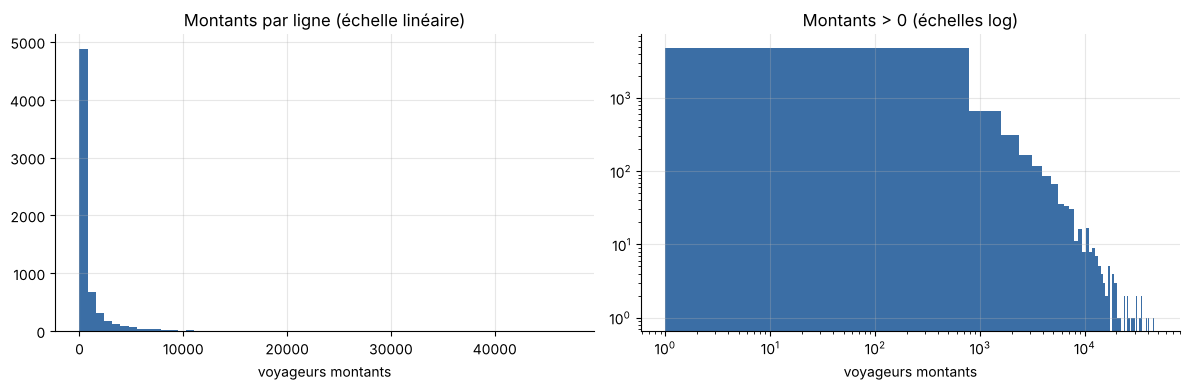

,montants
count,6537.0
mean,984.0
std,2647.0
min,0.0
25%,42.0
50%,201.0
75%,801.0
95%,4390.0
99%,11823.0
max,47213.0


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
s = sql("SELECT somme_de_montants FROM comptages")["somme_de_montants"]
axes[0].hist(s, bins=60, color="#3b6ea5")
axes[0].set_title("Montants par ligne (échelle linéaire)")
axes[1].hist(s[s > 0], bins=60, color="#3b6ea5", log=True)
axes[1].set_xscale("log")
axes[1].set_title("Montants > 0 (échelles log)")
for a in axes: a.set_xlabel("voyageurs montants")
plt.tight_layout(); plt.show()
s.describe(percentiles=[.25, .5, .75, .95, .99]).round(0).to_frame("montants")

In [8]:
sql("""
SELECT tranche_horaire, type_jour, count(*) AS lignes, round(avg(somme_de_montants)) AS moyenne,
       count(*) FILTER (WHERE somme_de_montants = 0) AS zeros
FROM comptages GROUP BY ALL ORDER BY type_jour, tranche_horaire
""").pivot(index="tranche_horaire", columns="type_jour", values="moyenne")

type_jour,DIM,JOB,SAM
tranche_horaire,,,
Après 20h,405.0,497.0,605.0
Avant 6h,41.0,148.0,65.0
De 10h à 16h,1289.0,1495.0,1658.0
De 16h à 20h,1046.0,2378.0,1321.0
De 6h à 10h,387.0,2304.0,687.0


**Constat 2.3 : nomenclature horaire à 5 tranches.** `Avant 6h`, `De 6h à 10h`, `De 10h à 16h`,
`De 16h à 20h`, `Après 20h`. La pointe du matin est donc *6h-10h* (pas 7h-9h) : les règles de
« pointe » doivent utiliser ces tranches. Le profil JOB montre bien les deux pointes.

In [9]:
sql("""
SELECT nom_gare, ligne, type_jour, tranche_horaire, date
FROM comptages WHERE somme_de_montants = 0 ORDER BY tranche_horaire, nom_gare
""").groupby("tranche_horaire").size().to_frame("zeros")

,zeros
tranche_horaire,
Après 20h,29
Avant 6h,34
De 6h à 10h,3


**Constat 2.4 : les zéros sont rares (66 lignes) et concentrés `Avant 6h` / `Après 20h`.**
Un zéro hors pointe est plausible (petite gare, peu de trains) ; un zéro en pointe JOB serait
suspect. On garde l'idée de la règle « faux zéro en pointe », adaptée aux tranches réelles.

### 2.5 Unicité : quelle est la vraie clé ?

In [10]:
sql("""
SELECT 'sans axe' AS cle, count(*) AS cles_en_double FROM (
  SELECT code_gare, date, type_jour, tranche_horaire, ligne FROM comptages GROUP BY ALL HAVING count(*) > 1)
UNION ALL
SELECT 'avec axe', count(*) FROM (
  SELECT code_gare, date, type_jour, tranche_horaire, ligne, axe FROM comptages GROUP BY ALL HAVING count(*) > 1)
""")

,cle,cles_en_double
0,sans axe,141
1,avec axe,0


In [11]:
sql("""
SELECT nom_gare, ligne, axe, type_jour, tranche_horaire, somme_de_montants
FROM comptages WHERE nom_gare = 'BOIS-COLOMBES' AND tranche_horaire = 'Après 20h' ORDER BY type_jour, axe
""")

,nom_gare,ligne,axe,type_jour,tranche_horaire,somme_de_montants
0,BOIS-COLOMBES,J,J4,DIM,Après 20h,311
1,BOIS-COLOMBES,J,J6,DIM,Après 20h,21
2,BOIS-COLOMBES,J,J4,JOB,Après 20h,470
3,BOIS-COLOMBES,J,J6,JOB,Après 20h,32
4,BOIS-COLOMBES,J,J4,SAM,Après 20h,640
5,BOIS-COLOMBES,J,J6,SAM,Après 20h,82


**Constat 2.5 : les « doublons » n'en sont pas.** Une même gare peut être desservie par
plusieurs **axes** d'une même ligne (ex. Bois-Colombes sur J4 et J6) avec des montants très
différents. La clé d'unicité doit inclure `axe` ; avec elle, il n'y a **aucun doublon**.

### 2.6 Cohérence entre la date et le type de jour

In [12]:
incoherences = sql("""
SELECT date, dayname(date) AS jour_calendaire, type_jour, ligne, count(*) AS lignes
FROM comptages
WHERE (type_jour = 'JOB' AND isodow(date) > 5)
   OR (type_jour = 'SAM' AND isodow(date) <> 6)
   OR (type_jour = 'DIM' AND isodow(date) <> 7)
GROUP BY ALL ORDER BY date
""")
incoherences

,date,jour_calendaire,type_jour,ligne,lignes
0,2024-02-04,Sunday,JOB,D,48
1,2024-08-06,Tuesday,SAM,U,11
2,2025-01-04,Saturday,JOB,J,70
3,2025-09-02,Tuesday,DIM,C,407
4,2025-11-02,Sunday,JOB,C,114
5,2026-10-01,Thursday,SAM,J,55


In [13]:
sql("""
WITH c AS (
  SELECT DISTINCT date, type_jour FROM comptages
  WHERE (type_jour = 'JOB' AND isodow(date) > 5) OR (type_jour = 'SAM' AND isodow(date) <> 6)
     OR (type_jour = 'DIM' AND isodow(date) <> 7))
SELECT date AS date_publiee, type_jour,
       make_date(year(date), day(date)::INT, month(date)::INT) AS date_inversee,
       dayname(make_date(year(date), day(date)::INT, month(date)::INT)) AS jour_si_inversee
FROM c WHERE day(date) <= 12 ORDER BY date
""")

,date_publiee,type_jour,date_inversee,jour_si_inversee
0,2024-02-04,JOB,2024-04-02,Tuesday
1,2024-08-06,SAM,2024-06-08,Saturday
2,2025-01-04,JOB,2025-04-01,Tuesday
3,2025-09-02,DIM,2025-02-09,Sunday
4,2025-11-02,JOB,2025-02-11,Tuesday
5,2026-10-01,SAM,2026-01-10,Saturday


**Constat 2.6 (majeur) : inversion jour/mois.** Plusieurs campagnes portent une date dont le jour
de la semaine contredit le type de jour (un « JOB » un dimanche…). Dans **tous** les cas, inverser
le jour et le mois redonne un jour cohérent (ex. `2025-11-02` JOB → `2025-02-11`, un mardi).
C'est la signature classique d'une confusion de format `JJ/MM` ↔ `MM/JJ` à la publication.

→ Nouvelle règle technique : **cohérence date / type de jour**, avec proposition de date corrigée
quand l'inversion est la seule explication. La ligne passe en `ATTENTION` (corrigée, tracée dans le
lineage) plutôt qu'en `ERREUR`, car le comptage lui-même n'est pas en cause.

In [14]:
sql("SELECT date, type_jour, dayname(date) AS jour, count(*) AS lignes FROM comptages WHERE date > current_date GROUP BY ALL")

,date,type_jour,jour,lignes
0,2026-11-01,DIM,Sunday,55


**Constat 2.7 : des dates dans le futur.** Des campagnes sont datées après la date du jour.
Ici aussi l'inversion jour/mois donne une date passée cohérente : à traiter par la même règle.

## 3. SNCF : fréquentation annuelle des gares (`frequentation-gares`)

Totaux annuels de voyageurs par gare (national). Utile comme **ordre de grandeur** et pour
contrôler la cohérence annuelle de l'extrapolation du compte officiel.

In [15]:
FREQ = latest("sncf_frequentation_gares")
con.execute(f"CREATE OR REPLACE VIEW frequentation AS SELECT * EXCLUDE (ingest_date) FROM '{FREQ}'")
cols = sql("DESCRIBE frequentation")["column_name"].tolist()
print(len(cols), "colonnes :", ", ".join(cols))

27 colonnes : nom_gare, code_uic_complet, code_postal, direction_regionale_gares, segmentation_drg, segmentation_marketing, non_voyageurs, total_voyageurs_2024, total_voyageurs_non_voyageurs_2024, total_voyageurs_2023, total_voyageurs_non_voyageurs_2023, total_voyageurs_2022, total_voyageurs_non_voyageurs_2022, total_voyageurs_2021, total_voyageurs_non_voyageurs_2021, total_voyageurs_2020, total_voyageurs_non_voyageurs_2020, total_voyageurs_2019, total_voyageurs_non_voyageurs_2019, total_voyageurs_2018, total_voyageurs_non_voyageurs_2018, totalvoyageurs2017, total_voyageurs_non_voyageurs_2017, total_voyageurs_2016, total_voyageurs_non_voyageurs_2016, total_voyageurs_2015, total_voyageurs_non_voyageurs_2015


**Constat 3.1 : dérive de nommage dans le schéma.** L'année 2017 s'appelle `totalvoyageurs2017`
alors que les autres suivent `total_voyageurs_AAAA`. Un contrat de schéma doit tolérer et
normaliser ce genre d'écart (règle « dérive de schéma »).

In [16]:
sql("""
SELECT count(*) AS gares_france,
       count(*) FILTER (WHERE left(code_postal, 2) IN ('75','77','78','91','92','93','94','95')) AS gares_idf,
       count(DISTINCT c.code_gare) AS gares_comptees,
       count(DISTINCT c.code_gare) FILTER (WHERE f.code_uic_complet IS NOT NULL) AS gares_comptees_trouvees
FROM frequentation f FULL JOIN (SELECT DISTINCT code_gare FROM comptages) c ON c.code_gare = f.code_uic_complet
""")

,gares_france,gares_idf,gares_comptees,gares_comptees_trouvees
0,3027,410,390,384


In [17]:
sql("""
SELECT f.nom_gare, f.total_voyageurs_2024 AS annuel_2024,
       round(sum(c.somme_de_montants) FILTER (WHERE c.type_jour = 'JOB')) AS montants_job_campagne
FROM frequentation f JOIN comptages c ON c.code_gare = f.code_uic_complet
GROUP BY ALL ORDER BY annuel_2024 DESC LIMIT 10
""")

,nom_gare,annuel_2024,montants_job_campagne
0,Paris Saint-Lazare,114093491,153527.0
1,Paris Montparnasse,68925312,38538.0
2,Paris Est,42725621,40660.0
3,Juvisy-sur-Orge,41881077,68146.0
4,Magenta,38771197,55668.0
5,Haussmann Saint-Lazare,38268052,56357.0
6,Saint-Denis,36960585,46741.0
7,La Défense,31729688,52872.0
8,Aulnay-sous-Bois,31683770,39569.0
9,Bibliothèque François Mitterrand,26975545,52610.0


**Constat 3.2 : les codes UIC des comptages se retrouvent presque tous dans le référentiel
SNCF** (jointure directe sur `code_gare = code_uic_complet`). Le format UIC à 8 chiffres
commençant par `87` est respecté partout : la règle de format reste utile comme garde-fou.

## 4. IDFM : validations par jour sur le réseau ferré

Nombre de validations (passes Navigo, tickets…) par **jour**, par **arrêt** et par **catégorie
de titre**. IDFM publie un jeu par trimestre ; on lit les quatre et on les compare.

In [18]:
schemas = []
for t in "1234":
    path = latest(f"idfm_validations_ferre_jour_t{t}")
    for name, typ, *_ in con.execute(f"DESCRIBE SELECT * EXCLUDE (ingest_date) FROM '{path}'").fetchall():
        schemas.append({"trimestre": f"T{t}", "colonne": name, "type": typ})
pd.DataFrame(schemas).pivot(index="colonne", columns="trimestre", values="type").fillna("— absente —")

trimestre,T1,T2,T3,T4
colonne,,,,
categorie_titre,VARCHAR,VARCHAR,VARCHAR,VARCHAR
code_stif_arret,VARCHAR,VARCHAR,VARCHAR,VARCHAR
code_stif_res,VARCHAR,VARCHAR,VARCHAR,VARCHAR
code_stif_trns,VARCHAR,DOUBLE,VARCHAR,VARCHAR
id_zdc,— absente —,DOUBLE,VARCHAR,DOUBLE
ida,DOUBLE,— absente —,— absente —,— absente —
jour,DATE,DATE,DATE,DATE
libelle_arret,VARCHAR,VARCHAR,VARCHAR,VARCHAR
nb_vald,BIGINT,DOUBLE,VARCHAR,BIGINT


**Constat 4.1 (majeur) : dérive de schéma d'un trimestre à l'autre.**
- l'identifiant de zone de correspondance s'appelle `ida` au T1 et `id_zdc` ailleurs ;
- les types changent (`nb_vald` en entier, réel ou texte ; `id_zdc` en réel ou texte, d'où des
  valeurs `71370.0` et `71370` pour la même gare).

→ La couche silver doit **normaliser** (renommer, typer) avant toute règle, et la règle
« contrat de schéma » doit signaler ces écarts dans le Dashboard 0/1.

In [19]:
parts = []
for t in "1234":
    path = latest(f"idfm_validations_ferre_jour_t{t}")
    zdc = "ida" if t == "1" else "id_zdc"
    parts.append(f"""SELECT 'T{t}' AS trimestre, jour, try_cast(code_stif_trns AS DOUBLE)::INT AS code_trns,
        code_stif_res AS code_res, code_stif_arret AS code_arret, try_cast({zdc} AS DOUBLE)::BIGINT AS id_zdc,
        libelle_arret, categorie_titre, nb_vald::VARCHAR AS nb_vald_brut FROM '{path}'""")
con.execute("CREATE OR REPLACE TABLE validations AS " + " UNION ALL ".join(parts))
sql("""
SELECT trimestre, min(jour) AS du, max(jour) AS au, count(*) AS lignes, count(DISTINCT id_zdc) AS zones,
       count(*) FILTER (WHERE try_cast(nb_vald_brut AS BIGINT) IS NULL) AS non_numeriques,
       min(try_cast(nb_vald_brut AS BIGINT)) AS min_vald
FROM validations GROUP BY trimestre ORDER BY du
""")

,trimestre,du,au,lignes,zones,non_numeriques,min_vald
0,T3,2025-07-01,2025-09-30,468226,746,0,1
1,T4,2025-10-01,2025-12-31,480645,746,0,1
2,T1,2026-01-01,2026-03-31,458336,724,0,1
3,T2,2026-04-01,2026-06-30,464229,724,0,1


**Constat 4.2 : pas de « Moins de 5 » dans les jeux actuels.** Toutes les valeurs sont numériques
et ≥ 1 : IDFM n'écrit plus la mention texte mais **n'émet pas les lignes sous le seuil**. La règle
reste nécessaire (les anciens fichiers l'utilisaient et le format peut revenir), mais il faut aussi
savoir qu'une catégorie absente un jour donné peut signifier « moins de 5 » et non « zéro ».
La couverture est de **365 jours consécutifs** (juillet 2025 → juin 2026).

In [20]:
sql("SELECT categorie_titre, count(*) AS lignes, sum(try_cast(nb_vald_brut AS BIGINT)) AS validations FROM validations GROUP BY ALL ORDER BY validations DESC")

,categorie_titre,lignes,validations
0,Forfait Navigo,279505,1.189215e+09
1,Forfaits courts,277213,3.999616e+08
2,Imagine R,278329,3.580980e+08
3,Contrat Solidarité Transport,205600,1.470848e+08
4,Contrat Solidarite Transport,71214,5.307502e+07
5,Amethyste,266111,4.014626e+07
6,NON DEFINI,247525,2.676916e+07
7,Autres titres,245939,1.703378e+07


**Constat 4.3 : libellés non normalisés.** « Contrat Solidarité Transport » et « Contrat Solidarite
Transport » (sans accent) coexistent ; « NON DEFINI » représente une part non négligeable. La
silver doit normaliser les catégories (sans accent, casse) avant agrégation.

In [21]:
sql("""
SELECT 'jour + zone + catégorie' AS cle, count(*) AS cles_en_double FROM (
  SELECT jour, id_zdc, categorie_titre FROM validations GROUP BY ALL HAVING count(*) > 1)
UNION ALL
SELECT '+ transporteur, réseau, arrêt', count(*) FROM (
  SELECT jour, code_trns, code_res, code_arret, id_zdc, categorie_titre FROM validations GROUP BY ALL HAVING count(*) > 1)
""")

,cle,cles_en_double
0,jour + zone + catégorie,83616
1,"+ transporteur, réseau, arrêt",644


In [22]:
sql("""
SELECT id_zdc, any_value(libelle_arret) AS gare, list(DISTINCT code_trns ORDER BY code_trns) AS transporteurs,
       count(DISTINCT code_arret) AS arrets
FROM validations GROUP BY id_zdc HAVING count(DISTINCT code_arret) > 1 ORDER BY arrets DESC LIMIT 8
""")

,id_zdc,gare,transporteurs,arrets
0,71517,LA DEFENSE,"[100, 800, 810]",4
1,73626,GARE DE LYON,"[100, 800, 810]",3
2,71379,PORTE MAILLOT,"[100, 800]",3
3,73620,SAINT-MICHEL,"[100, 800, 810]",3
4,72641,BOURGET T11,"[764, 800, 810]",2
5,71673,NATION,"[100, 810]",2
6,71274,INVALIDES,"[100, 800]",2
7,73731,ST CYR,[800],2


In [23]:
dups = sql("""
SELECT trimestre, jour, code_trns, code_arret, id_zdc, libelle_arret, categorie_titre, nb_vald_brut
FROM validations
WHERE (jour, code_trns, code_res, code_arret, id_zdc, categorie_titre) IN (
  SELECT (jour, code_trns, code_res, code_arret, id_zdc, categorie_titre) FROM validations GROUP BY ALL HAVING count(*) > 1)
ORDER BY jour, id_zdc, categorie_titre
""")
print(dups.groupby("trimestre").size().to_string(), "\n")
dups.head(6)

trimestre
T4    1288 



,trimestre,jour,code_trns,code_arret,id_zdc,libelle_arret,categorie_titre,nb_vald_brut
0,T4,2025-10-01,100,689,71545,PTE DE CLICHY,Amethyste,156
1,T4,2025-10-01,100,689,71545,PTE DE CLICHY,Amethyste,583
2,T4,2025-10-01,100,689,71545,PTE DE CLICHY,Autres titres,38
3,T4,2025-10-01,100,689,71545,PTE DE CLICHY,Autres titres,723
4,T4,2025-10-01,100,689,71545,PTE DE CLICHY,Contrat Solidarite Transport,2383
5,T4,2025-10-01,100,689,71545,PTE DE CLICHY,Contrat Solidarite Transport,535


**Constat 4.5 : une zone regroupe plusieurs arrêts, et le T4 contient de vrais doublons.**
- Une **zone de correspondance** regroupe souvent plusieurs arrêts et transporteurs (ex. une gare
  exploitée en partie par la RATP et en partie par la SNCF) : le volume d'une gare = **somme** sur
  ses arrêts. Ce ne sont pas des doublons.
- Sur la clé complète (transporteur, réseau, arrêt, zone, catégorie, jour), il reste **644 doublons,
  tous au T4**, avec des valeurs *différentes* (ex. Porte de Clichy) : deux flux publiés sous le
  même code. On ne peut pas savoir lequel est « le bon » ; l'hypothèse la plus probable est deux
  points de validation distincts. → RT_04 les signale en `ATTENTION` et la silver les **additionne**,
  décision tracée dans le lineage.

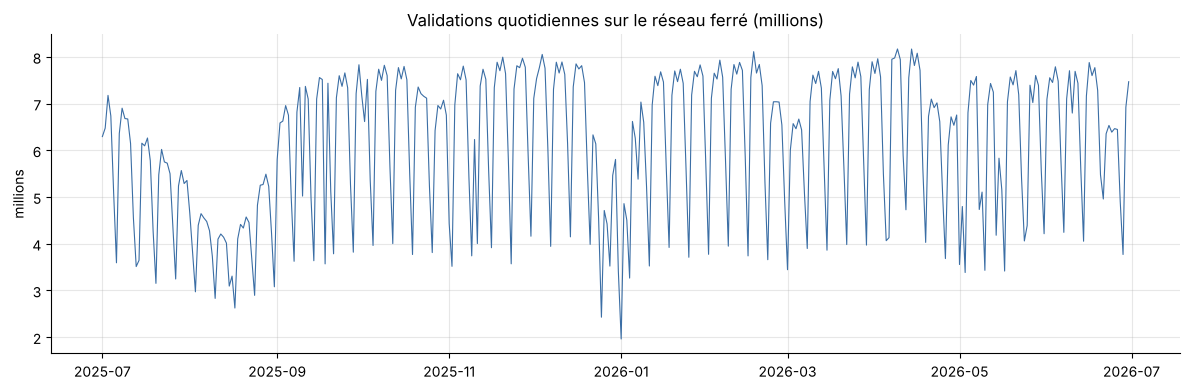

In [24]:
jour = sql("SELECT jour, sum(try_cast(nb_vald_brut AS BIGINT)) / 1e6 AS millions FROM validations GROUP BY jour ORDER BY jour")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(jour["jour"], jour["millions"], lw=.8, color="#3b6ea5")
ax.set_title("Validations quotidiennes sur le réseau ferré (millions)")
ax.set_ylabel("millions"); plt.tight_layout(); plt.show()

**Constat 4.4 : saisonnalité lisible.** Rythme hebdomadaire très marqué (creux les week-ends),
creux estival d'août et des fêtes de fin d'année. C'est la base de la règle d'outlier contextuel
(comparer une valeur à sa distribution *pour le même type de jour et la même période*).

In [25]:
sql("""
SELECT any_value(libelle_arret) AS gare, id_zdc,
       round(sum(try_cast(nb_vald_brut AS BIGINT)) / count(DISTINCT jour)) AS moyenne_jour
FROM validations GROUP BY id_zdc ORDER BY moyenne_jour DESC LIMIT 10
""")

,gare,id_zdc,moyenne_jour
0,SAINT-LAZARE,71370,227277.0
1,LA DEFENSE,71517,156275.0
2,CHATELET,71264,146335.0
3,GARE DE LYON,73626,139482.0
4,GARE DU NORD,71410,138165.0
5,MONTPARNASSE,71139,122682.0
6,GARE DE L'EST,71359,87977.0
7,CH.D.G.ETOILE,71347,52956.0
8,LES HALLES,73794,49202.0
9,SAINT-MICHEL,73620,48610.0


## 5. IDFM : profils horaires par jour type

Part (%) des validations de chaque **heure** pour une gare et un **type de jour**. C'est ce qui
permettra de répartir un volume journalier IDFM sur les 5 tranches horaires SNCF.

In [26]:
PROFIL = latest("idfm_validations_ferre_profils_horaires_t2")
con.execute(f"CREATE OR REPLACE VIEW profils AS SELECT * EXCLUDE (ingest_date) FROM '{PROFIL}'")
sql("SELECT cat_jour, count(*) AS lignes, count(DISTINCT id_zdc) AS zones FROM profils GROUP BY ALL ORDER BY cat_jour")

,cat_jour,lignes,zones
0,DIJFP,17094,724
1,JOHV,17206,724
2,JOVS,16392,724
3,SAHV,16503,724
4,SAVS,15976,723


Codes de type de jour : `JOHV` jour ouvré hors vacances, `JOVS` jour ouvré vacances scolaires,
`SAHV` / `SAVS` samedi hors / pendant vacances, `DIJFP` dimanche et jours fériés (et ponts).
**C'est plus fin que la SNCF** (`JOB`, `SAM`, `DIM`) : il faudra une table de correspondance,
et le calendrier scolaire de la zone C pour choisir le bon profil.

In [27]:
ecarts = sql("""
SELECT id_zdc, code_stif_arret, cat_jour, round(sum(pourcentage_validations), 2) AS total_pct
FROM profils GROUP BY ALL
""")
print("Profils dont la somme s'écarte de 100 % de plus d'un point :",
      (ecarts.total_pct.sub(100).abs() > 1).sum(), "sur", len(ecarts))
ecarts.total_pct.describe().round(2).to_frame()

Profils dont la somme s'écarte de 100 % de plus d'un point : 5 sur 3819


,total_pct
count,3819.00
mean,100.13
std,3.62
min,99.95
25%,99.99
50%,100.00
75%,100.01
max,200.01


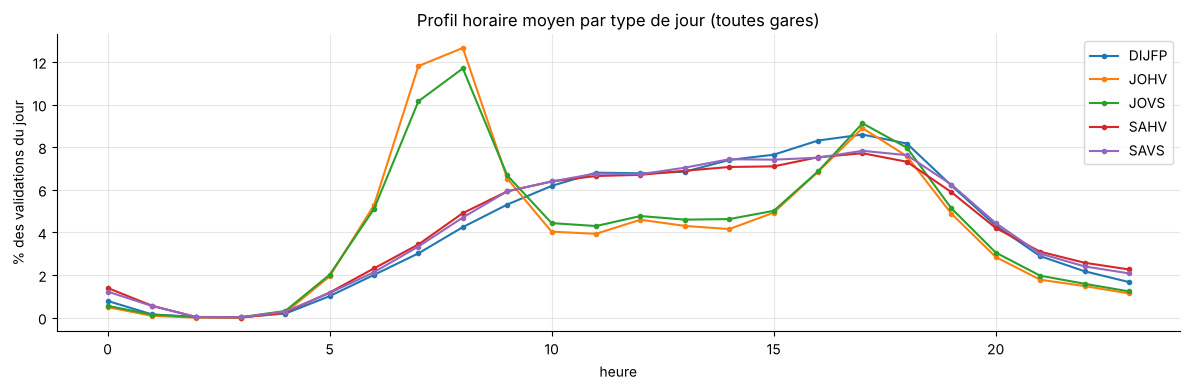

In [28]:
p = sql("""
SELECT trnc_horr_60, cat_jour, avg(pourcentage_validations) AS pct FROM profils
WHERE trnc_horr_60 <> 'ND' GROUP BY ALL
""")
p["heure"] = p.trnc_horr_60.str.extract(r"^(\d+)H").astype(float)
fig, ax = plt.subplots(figsize=(12, 4))
for cat, g in p.sort_values("heure").groupby("cat_jour"):
    ax.plot(g.heure, g.pct, marker="o", ms=3, label=cat)
ax.set_xlabel("heure"); ax.set_ylabel("% des validations du jour"); ax.legend()
ax.set_title("Profil horaire moyen par type de jour (toutes gares)"); plt.tight_layout(); plt.show()

**Constat 5.1 : les profils somment bien à ~100 %** (aux arrondis près) : on peut les utiliser
comme clés de répartition. Quelques profils (5 sur ~3 800) montent à 200 % : un arrêt publié deux
fois, à dédoublonner avant usage. Les deux pointes JOHV sont nettes (7h-9h et 17h-19h).

## 6. Contexte : calendrier scolaire, jours fériés, météo

In [29]:
CAL = latest("education_calendrier_scolaire")
sql(f"""
SELECT description, start_date::DATE AS debut, end_date::DATE AS fin
FROM '{CAL}' WHERE zones = 'Zone C' AND annee_scolaire IN ('2024-2025', '2025-2026')
  AND population IN ('-', 'Élèves') ORDER BY debut
""")

,description,debut,fin
0,Vacances de la Toussaint,2024-10-18,2024-11-03
1,Vacances de la Toussaint,2024-10-18,2024-11-03
2,Vacances de la Toussaint,2024-10-18,2024-11-03
3,Vacances de la Toussaint,2024-10-18,2024-11-03
4,Vacances de la Toussaint,2024-10-18,2024-11-03
5,Vacances de Noël,2024-12-20,2025-01-05
6,Vacances de Noël,2024-12-20,2025-01-05
7,Vacances de Noël,2024-12-20,2025-01-05
8,Vacances de Noël,2024-12-20,2025-01-05
9,Vacances de Noël,2024-12-20,2025-01-05


**Constat 6.1 :** les dates sont en UTC (`22:00+00` = minuit à Paris) ; il faut convertir en
heure de Paris avant de tester « est-ce un jour de vacances ? », sinon on se décale d'un jour.
Île-de-France = **zone C**.

285 jours fériés, ex. : [('2006-11-01', 'Toussaint'), ('2006-11-11', '11 novembre'), ('2006-12-25', 'Jour de Noël')]
Météo : 216 heures, de 2026-10-19 00:00:00 à 2026-10-27 23:00:00


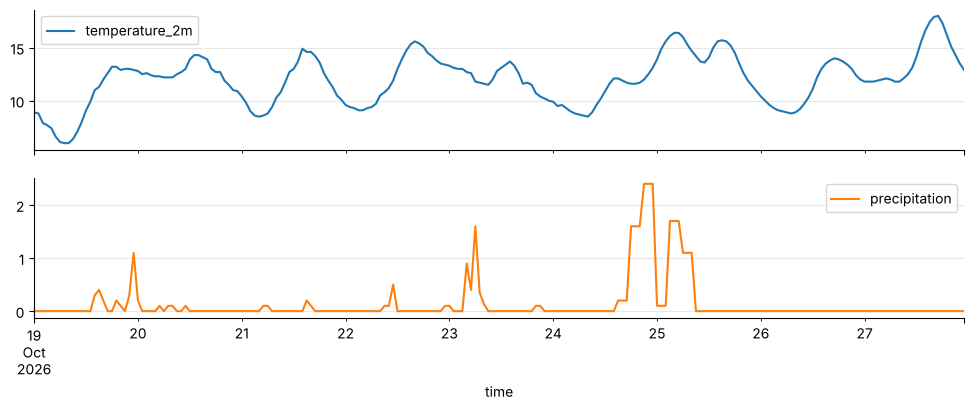

In [30]:
FERIES = latest("jours_feries_metropole")
feries = read_json(FERIES)
print(len(feries), "jours fériés, ex. :", list(feries.items())[-3:])
METEO = latest("openmeteo_prevision_paris")
meteo = read_json(METEO)
m = pd.DataFrame(meteo["hourly"]); m["time"] = pd.to_datetime(m["time"])
print("Météo :", len(m), "heures, de", m.time.min(), "à", m.time.max())
m.set_index("time")[["temperature_2m", "precipitation"]].plot(subplots=True, figsize=(12, 4)); plt.show()

## 7. PRIM : temps réel (SIRI Estimated Timetable)

Un instantané de toutes les courses en cours sur le réseau IDFM (tous modes).

In [31]:
PRIM = latest("prim_estimated_timetable")
siri = read_json(PRIM)
courses = siri["Siri"]["ServiceDelivery"]["EstimatedTimetableDelivery"][0]["EstimatedJourneyVersionFrame"][0]["EstimatedVehicleJourney"]
modes = pd.Series([",".join(c.get("VehicleMode", [])) or "(non renseigné)" for c in courses]).value_counts()
print(len(courses), "courses dans l'instantané"); modes.to_frame("courses")

16781 courses dans l'instantané


,courses
BUS,13203
RAIL,1338
(non renseigné),1163
METRO,727
TRAM,350


In [32]:
trains = [c for c in courses if "RAIL" in c.get("VehicleMode", [])]
rows = []
for c in trains:
    for call in c.get("EstimatedCalls", {}).get("EstimatedCall", []):
        rows.append({"ligne": (c.get("PublishedLineName") or [{}])[0].get("value"),
                     "numero_train": (c.get("VehicleJourneyName") or [{}])[0].get("value"),
                     "mission": (c.get("JourneyNote") or [{}])[0].get("value"),
                     "statut_depart": call.get("DepartureStatus"), "statut_arrivee": call.get("ArrivalStatus")})
appels = pd.DataFrame(rows)
print(len(trains), "trains,", len(appels), "passages en gare")
appels.groupby("ligne").numero_train.nunique().sort_values(ascending=False).to_frame("trains").T

1338 trains, 18321 passages en gare


ligne,A,C,D,B,L,J,H,E,P,N,TER Hauts-de-France,TER Normandie,R,V,U,TER Centre - Val de Loire,TER Grand-Est,K,TER Centre - Val de Loire,TER Bourgogne - Franche-Comte,T13,T12
trains,174,141,128,122,121,103,99,86,56,48,38,28,25,23,21,19,10,9,8,8,0,0


In [33]:
appels.statut_depart.fillna("(absent)").value_counts().to_frame("passages")

,passages
statut_depart,
ON_TIME,16895
NO_REPORT,737
DELAYED,309
CANCELLED,309
(absent),71


**Constat 7.1 :** PRIM donne bien, **par train** (numéro, code mission), les statuts
`ON_TIME`, `DELAYED`, `CANCELLED`… C'est la seule source « par train » : les règles sur l'offre
réalisée (train supprimé, retard) s'appliqueront à l'agrégat *(gare, tranche horaire)* via le
**nombre de trains réellement passés**, pas au comptage lui-même. Un instantané par jour ne suffit
pas à reconstituer toute l'offre réalisée : il faudra une collecte plus fréquente (sur VPS).

## 8. Faisabilité des croisements SNCF ↔ IDFM

La règle phare (capteurs SNCF vs portillons IDFM) suppose deux choses : relier les **gares** et
relier les **périodes**.

In [34]:
sql("""
SELECT count(*) AS lignes_comptage,
       count(*) FILTER (WHERE date BETWEEN (SELECT min(jour) FROM validations) AND (SELECT max(jour) FROM validations))
         AS dans_la_periode_idfm
FROM comptages
""")

,lignes_comptage,dans_la_periode_idfm
0,6537,929


**Constat 8.1 : très peu de recouvrement temporel jour à jour.** Les campagnes SNCF sont
anciennes ou ponctuelles, alors qu'IDFM ne publie que les 12 derniers mois. Comparer « le même
jour » laisse presque tout en `PAS TESTÉ`.

→ Adaptation : comparer la **journée type** SNCF (JOB/SAM/DIM) à la **moyenne IDFM du même type
de jour** sur la période disponible. C'est d'ailleurs ce que représente une campagne de comptage.

In [35]:
REF_SNCF = latest("sncf_liste_gares") if con.execute("SELECT count(*) FROM bronze_raw.files WHERE source='sncf_liste_gares'").fetchone()[0] else None
REF_IDFM = latest("idfm_emplacement_gares") if con.execute("SELECT count(*) FROM bronze_raw.files WHERE source='idfm_emplacement_gares'").fetchone()[0] else None
for nom, ref in [("SNCF liste des gares", REF_SNCF), ("IDFM emplacement des gares", REF_IDFM)]:
    print(nom, ":", "pas encore collecté" if ref is None else
          ", ".join(r[0] for r in con.execute(f"DESCRIBE SELECT * FROM '{ref}'").fetchall()))

SNCF liste des gares : code_uic, libelle, fret, voyageurs, code_ligne, rg_troncon, pk, commune, departemen, idreseau, idgaia, x_l93, y_l93, x_wgs84, y_wgs84, c_geo, geo_point_2d, geo_shape, ingest_date
IDFM emplacement des gares : geo_point_2d, geo_shape, objectid_1, id_gares, nom_gares, nom_so_gar, nom_su_gar, id_ref_zdc, nom_zdc, id_ref_zda, nom_zda, idrefliga, idrefligc, res_com, indice_lig, mode, tertrain, terrer, termetro, tertram, terval, exploitant, idf, principal, x, y, picto, nom_iv, ingest_date


**Constat 8.2 : pas de clé commune.** La SNCF identifie les gares par **code UIC**, IDFM par
**zone de correspondance** (`id_zdc`). Aucun des jeux de validations ne porte les deux.

→ On construit une **table de correspondance UIC ↔ ZdC explicable** à l'étape 2B à partir des
deux référentiels (coordonnées + nom normalisé). Chaque appariement aura sa propre preuve
(distance en mètres, similarité de nom) et son statut, comme n'importe quelle donnée.

**Test de faisabilité.** Les deux référentiels donnent des coordonnées en Lambert 93 (mètres).
Pour chaque gare comptée par la SNCF, on cherche la zone de correspondance IDFM ferrée la plus proche.

In [36]:
appariement = sql(f"""
WITH sncf AS (
  SELECT DISTINCT c.code_gare, c.nom_gare, g.x_l93 AS x, g.y_l93 AS y
  FROM comptages c LEFT JOIN (SELECT DISTINCT code_uic, x_l93, y_l93 FROM '{REF_SNCF}') g ON g.code_uic = c.code_gare),
idfm AS (
  SELECT id_ref_zdc, any_value(nom_zdc) AS nom_zdc, avg(x) AS x, avg(y) AS y
  FROM '{REF_IDFM}' WHERE mode IN ('RER', 'TRAIN') GROUP BY id_ref_zdc)
SELECT s.code_gare, s.nom_gare, arg_min(i.nom_zdc, sqrt((s.x-i.x)^2 + (s.y-i.y)^2)) AS zdc_la_plus_proche,
       arg_min(i.id_ref_zdc, sqrt((s.x-i.x)^2 + (s.y-i.y)^2)) AS id_zdc,
       round(min(sqrt((s.x-i.x)^2 + (s.y-i.y)^2))) AS distance_m
FROM sncf s, idfm i GROUP BY ALL
""")
print("Gares comptées :", len(appariement), "| sans coordonnées SNCF :", appariement.distance_m.isna().sum())
print(appariement.distance_m.describe(percentiles=[.5, .9, .95, .99]).round(0).to_string())
appariement.sort_values("distance_m", ascending=False).head(8)

Gares comptées : 390 | sans coordonnées SNCF : 3
count     387.0
mean      124.0
std       527.0
min         0.0
50%        55.0
90%       169.0
95%       218.0
99%      1002.0
max      6942.0


,code_gare,nom_gare,zdc_la_plus_proche,id_zdc,distance_m
285,87116749,VILLIERS-MONTBARBIN,Esbly,68653,6942.0
72,87116772,CRECY-LA-CHAPELLE,Guérard - La Celle-sur-Morin,67924,6452.0
148,87116731,COUILLY-SAINT-GERMAIN-QUINCY,Esbly,68653,3943.0
297,87116400,MONTRY-CONDE,Esbly,68653,1803.0
256,87381020,NEUILLY-PORTE-MAILLOT,Charles-de-Gaulle Étoile,71347,872.0
223,87681379,GRIGNY-CENTRE,Grigny Centre,60797,451.0
14,87654798,ROSA-PARKS,Rosa Parks,73798,432.0
234,87393504,PETIT-JOUY-LES-LOGES,Petit Jouy Les Loges,63594,356.0


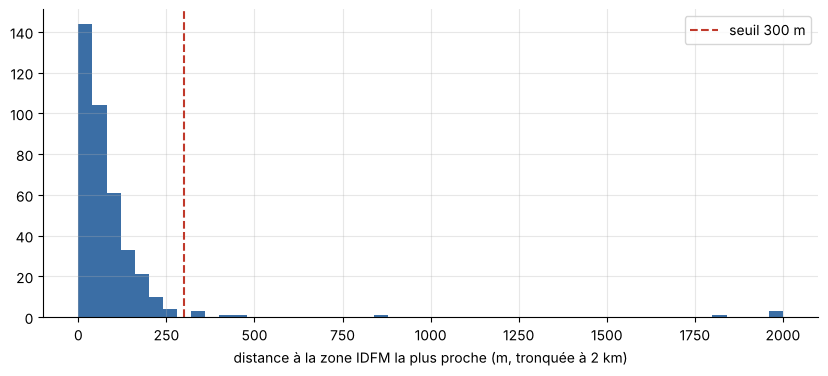

Part des gares appariées à moins de 300 m dont la zone a des validations IDFM :

 92.0 %


In [37]:
fig, ax = plt.subplots()
ax.hist(appariement.distance_m.dropna().clip(upper=2000), bins=50, color="#3b6ea5")
ax.axvline(300, color="#c0392b", ls="--", label="seuil 300 m")
ax.set_xlabel("distance à la zone IDFM la plus proche (m, tronquée à 2 km)"); ax.legend(); plt.show()
couverture = sql("SELECT DISTINCT id_zdc FROM validations")
print("Part des gares appariées à moins de 300 m dont la zone a des validations IDFM :",
      round(appariement[appariement.distance_m < 300].id_zdc.isin(couverture.id_zdc).mean() * 100, 1), "%")

**Constat 8.3 : l'appariement géographique est très majoritairement net** (médiane ~55 m,
95 % des gares à moins de ~220 m). Les cas lointains sont des gares desservies par un mode non
retenu dans le filtre (ex. le tram-train Esbly – Crécy) ou des gares dont le nom diffère : ils seront
`PAS TESTÉ` pour la règle croisée plutôt que forcés, et un contrôle de similarité de nom complétera
la distance.

## 9. Synthèse : revue des 20 règles à la lumière des données

| Règle | Verdict | Justification (constat) |
|---|---|---|
| **RT_01** Clés présentes | ✅ garder | 0 % de nuls aujourd'hui, mais garde-fou indispensable |
| **RT_02** Format UIC `87xxxxxx` | ✅ garder | 100 % conformes (§3.2) ; pour IDFM : `id_zdc` entier |
| **RT_03** Typage des comptages | ✏️ adapter | Plus de « Moins de 5 » mais types variables selon le trimestre (§4.1-4.2) |
| **RT_04** Unicité | ✏️ adapter | Clé SNCF = gare + ligne + **axe** + date + type de jour + tranche (§2.5) ; clé IDFM avec transporteur/arrêt (§4.5) |
| **RT_05** Mesure non nulle | ✅ garder | Aucune valeur manquante aujourd'hui |
| **RT_06** Gare dans le référentiel | ✏️ adapter | Référentiel = liste des gares SNCF (et non GTFS) (§3.2) |
| **RT_07** Date valide | ✏️ adapter | + **cohérence date / type de jour** et inversion jour/mois (§2.6-2.7) |
| **RT_08** Exhaustivité des tranches | ✏️ adapter | 5 tranches SNCF ; plusieurs gares n'en ont qu'une partie |
| **RT_09** Référentiel croisé dispo | ✏️ adapter | Dépend de la correspondance UIC ↔ ZdC (§8.2) |
| **RT_10** Contrat de schéma | ✅ renforcer | Dérives réelles : `ida`/`id_zdc`, types, `totalvoyageurs2017` (§3.1, §4.1) |
| **RM_01** Montants ≥ 0 | ✅ garder | Aucun négatif, garde-fou |
| **RM_02** Capacité d'une rame | ✏️ adapter | Pas de numéro de train : plafond par **(gare, tranche)** selon offre et capacité, ou bornes statistiques |
| **RM_03** Train supprimé | ⏸️ reporter | Pas de train dans les comptages ; à rebrancher sur PRIM à l'étape 3 (§7.1) |
| **RM_04** Terminus | ⏸️ reporter | Pas de mission dans les comptages |
| **RM_05** Faux zéro en pointe | ✏️ adapter | Tranches réelles `De 6h à 10h` / `De 16h à 20h` JOB (§2.3-2.4) |
| **RM_06** SNCF vs IDFM | ✏️ adapter | Comparaison en **journée type** et via table UIC ↔ ZdC (§8.1-8.2) |
| **RM_07** Profil pointe/creux | ✅ garder | Profils observables des deux côtés (§2.3, §5) |
| **RM_08** Week-end vs JOB | ✅ garder | Calculable par gare et par campagne |
| **RM_09** Outlier z-score | ✏️ adapter | Historique SNCF trop court par gare : z-score robuste (médiane/MAD) par ligne × tranche × type de jour |
| **RM_10** Train direct | ⏸️ reporter | Nécessite l'offre GTFS par train |

**Nouvelles règles proposées**
- **RT_11** Cohérence date / type de jour, avec correction tracée par inversion jour/mois.
- **RT_12** Normalisation des libellés (catégories de titres, identifiants `71370.0` → `71370`).

**Prochaine étape (2B)** : implémenter ces règles versionnées, la table de correspondance
UIC ↔ ZdC, le score de confiance et le lineage ligne par ligne, puis les Dashboards 1 et 2.